# TripGenie — Content-Based Travel Recommendations

## 1. Objective and approach
Build a reusable baseline that recommends destinations using the processed tourism catalogue. **TF-IDF** weights distinctive words and two-word phrases; **cosine similarity** compares their normalized vectors. We demonstrate destination-to-destination matching, free-text interest matching, and a weighted combination. Every example displays up to five unique destinations and similarity scores.

This is a content-based system without user interactions or learned preference weights. Scores indicate text similarity, not travel quality, probabilities, or verified suitability. Budget, season, permits, and accessibility constraints are not enforced by this baseline.

## 2. Load the processed catalogue and reusable implementation
The implementation lives in `backend/recommender/content_recommender.py`, independent of Flask and notebook state. Fit once at application startup, then reuse the object. Run with Python 3, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, and ipykernel. Source and processed files are read only.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, Markdown

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data" / "processed" / "india_tourism_processed.json").is_file()), None)
if root is None:
    raise FileNotFoundError("Run from within the TripGenie repository after preprocessing.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from backend.recommender.content_recommender import ContentBasedRecommender, destination_key

processed_path = root / "data" / "processed" / "india_tourism_processed.json"
source_path = root / "data" / "india_tourism_dataset.json"
input_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in [processed_path, source_path]}
records = json.loads(processed_path.read_text(encoding="utf-8"))
catalogue = pd.DataFrame(records)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def observe(text):
    display(Markdown("**Observations.** " + text))

def show_recommendations(results):
    display(results.style.format({"similarity_score": "{:.4f}", "destination_similarity": "{:.4f}",
                                  "interest_similarity": "{:.4f}", "ideal_days": "{:g}"}))

display(catalogue[["id", "destination_name", "state", "trip_types_clean", "tfidf_word_count"]].head())
observe(f"Loaded {len(catalogue)} entries. All source variants are retained during fitting; "
        "duplicate destination names are consolidated only in recommendation results.")

,id,destination_name,state,trip_types_clean,tfidf_word_count
0,1,Goa,Goa,"[beach, culture, food, nightlife, wellness, ph...",79
1,2,Ladakh (Leh),Ladakh,"[adventure, nature, culture, religious, photog...",83
2,3,Jaipur,Rajasthan,"[heritage, culture, photography, shopping, food]",79
3,4,Varanasi (Kashi),Uttar Pradesh,"[religious, spiritual, culture, photography]",84
4,5,Agra,Uttar Pradesh,"[heritage, photography, short break]",66


**Observations.** Loaded 100 entries. All source variants are retained during fitting; duplicate destination names are consolidated only in recommendation results.

## 3. Fit TF-IDF once and inspect its representation
The input is the preprocessing notebook's `tfidf_text`. Use English stopwords, unigrams and bigrams, sublinear term frequency, and L2 normalization. Bigram phrases can capture terms such as “water sports,” but phrase order in a free-text query matters. English stopwords are a baseline choice for this English-language catalogue; no parameter search or superiority claim is made.

The catalogue is the searchable corpus, so IDF is fitted across all its documents. Interest queries are transformed with the same fitted vocabulary. Unknown words contribute no features; fully unknown interest queries return no results rather than arbitrary zero-score rankings. Combined queries with fully unknown interests raise a clear error.

No dense all-pairs matrix is stored by the backend: each request compares a single vector against the sparse corpus.

TF-IDF shape: (100, 8326); nonzero weights: 14,329; fit time: 0.021 s


,TF-IDF weight
nightlife,0.176058
goa,0.156146
portuguese,0.154794
beach,0.152661
spice plantations,0.142043
spice,0.132995
plantations,0.111196
calangute beach,0.091424
temple church,0.091424
nightlife spice,0.091424


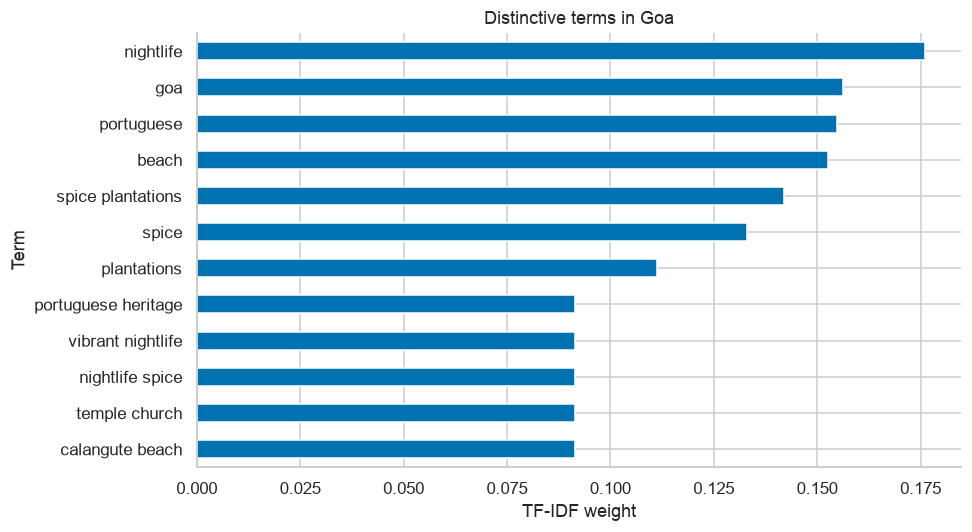

**Observations.** The fitted vocabulary has 8,326 terms and phrases. Weights are document features, not explanation scores for a particular recommendation.

In [2]:
start = time.perf_counter()
recommender = ContentBasedRecommender.from_json(processed_path)
fit_seconds = time.perf_counter() - start
matrix = recommender.tfidf_matrix
print(f"TF-IDF shape: {matrix.shape}; nonzero weights: {matrix.nnz:,}; fit time: {fit_seconds:.3f} s")
feature_names = recommender.vectorizer.get_feature_names_out()
first = matrix.getrow(0)
top_weights = pd.Series(first.data, index=feature_names[first.indices]).sort_values(ascending=False).head(12)
display(top_weights.rename("TF-IDF weight").to_frame())
fig, ax = plt.subplots(figsize=(9, 5))
top_weights.sort_values().plot.barh(ax=ax, color="#0072b2")
ax.set(title=f"Distinctive terms in {catalogue.iloc[0].destination_name}", xlabel="TF-IDF weight", ylabel="Term")
fig.tight_layout(); plt.show()
observe(f"The fitted vocabulary has {matrix.shape[1]:,} terms and phrases. "
        "Weights are document features, not explanation scores for a particular recommendation.")

## 4. Recommend from a selected destination
Use an original record ID to select an exact variant. Name lookup ignores case and surrounding/repeated whitespace; a repeated name in one location selects the first source entry. If a name occurs in different locations, use an ID to disambiguate it.

Candidates are ranked by cosine similarity, with original IDs breaking ties. Exclude **all** entries sharing the selected destination's normalized name. Then retain the highest-scoring variant of each candidate name. Facts are not merged across variants. This conservative policy may collapse same-named places in different locations; it is a display rule, not completed geographic entity resolution.

In [3]:
selected_id = 1
selected = catalogue.loc[catalogue.id.eq(selected_id)].iloc[0]
destination_results = recommender.recommend(selected_destination=selected_id, top_n=5)
print(f"Selected: {selected.destination_name} (ID {selected_id})")
show_recommendations(destination_results)
observe(f"Returned {len(destination_results)} unique destinations for {selected.destination_name}. "
        "Similarity reflects shared catalogue content; returned record IDs identify the selected variants.")

Selected: Goa (ID 1)


,id,destination_name,state,region,trip_types_clean,ideal_days,similarity_score,destination_similarity,interest_similarity
0,25,Gokarna,Karnataka,South India,"['beach', 'backpacking', 'pilgrimage', 'offbeat']",3,0.0798,0.0798,0.0000
1,87,Hidden Goa Coves (Butterfly & Nearby Beaches),Goa,West India,"['beach', 'offbeat', 'short break', 'photography']",2,0.0790,0.0790,0.0000
2,30,Varkala,Kerala,South India,"['beach', 'cliff scenery', 'wellness', 'backpacking', 'short break']",3,0.0702,0.0702,0.0000
3,3,Jaipur,Rajasthan,North India,"['heritage', 'culture', 'photography', 'shopping', 'food']",3,0.0456,0.0456,0.0000
4,53,Coorg (Kodagu),Karnataka,South India,"['coffee estates', 'hill station', 'nature', 'family', 'honeymoon']",3,0.0412,0.0412,0.0000


**Observations.** Returned 5 unique destinations for Goa. Similarity reflects shared catalogue content; returned record IDs identify the selected variants.

## 5. Recommend from user interests and combine both signals
Interest input accepts free text or a list of strings. The same text normalization used in preprocessing is applied before vectorization. In a combined query, the final score is

`destination_weight × destination cosine + (1 − destination_weight) × interest cosine`.

Here the weight is 0.4, so interests receive 60% of the score. This manually chosen weight demonstrates behavior, not a tuned personalization policy. With only a destination or only interests, that signal receives full weight. Show both components so a combined score is interpretable.

Interests: beach, water sports, snorkelling, island
Interest-only recommendations


,id,destination_name,state,region,trip_types_clean,ideal_days,similarity_score,destination_similarity,interest_similarity
0,61,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,Island Territory,"['island', 'beach', 'diving', 'honeymoon', 'family']",3,0.2169,0.0000,0.2169
1,62,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,Island Territory,"['island', 'beach', 'diving', 'offbeat', 'honeymoon']",2,0.2142,0.0000,0.2142
2,50,Kalpeni Island (Lakshadweep),Lakshadweep,Island Territory,"['island', 'water sports', 'offbeat', 'beach']",2,0.1890,0.0000,0.1890
3,49,Lakshadweep (Agatti–Bangaram–Kadmat circuit),Lakshadweep,Island Territory,"['island', 'beach', 'diving', 'honeymoon', 'offbeat']",5,0.1754,0.0000,0.1754
4,1,Goa,Goa,West India,"['beach', 'culture', 'food', 'nightlife', 'wellness', 'photography']",5,0.1318,0.0000,0.1318


Combined recommendations: Goa + interests


,id,destination_name,state,region,trip_types_clean,ideal_days,similarity_score,destination_similarity,interest_similarity
0,62,Neil Island (Shaheed Dweep),Andaman and Nicobar Islands,Island Territory,"['island', 'beach', 'diving', 'offbeat', 'honeymoon']",2,0.1439,0.0386,0.2142
1,61,Havelock Island (Swaraj Dweep),Andaman and Nicobar Islands,Island Territory,"['island', 'beach', 'diving', 'honeymoon', 'family']",3,0.1436,0.0337,0.2169
2,50,Kalpeni Island (Lakshadweep),Lakshadweep,Island Territory,"['island', 'water sports', 'offbeat', 'beach']",2,0.1241,0.0266,0.1890
3,49,Lakshadweep (Agatti–Bangaram–Kadmat circuit),Lakshadweep,Island Territory,"['island', 'beach', 'diving', 'honeymoon', 'offbeat']",5,0.1177,0.0311,0.1754
4,88,Bangaram & Kadmat Islands (Lakshadweep Quiet Beaches),Lakshadweep,Island Territory,"['island', 'snorkelling', 'offbeat beach', 'honeymoon']",4,0.0822,0.0151,0.1270


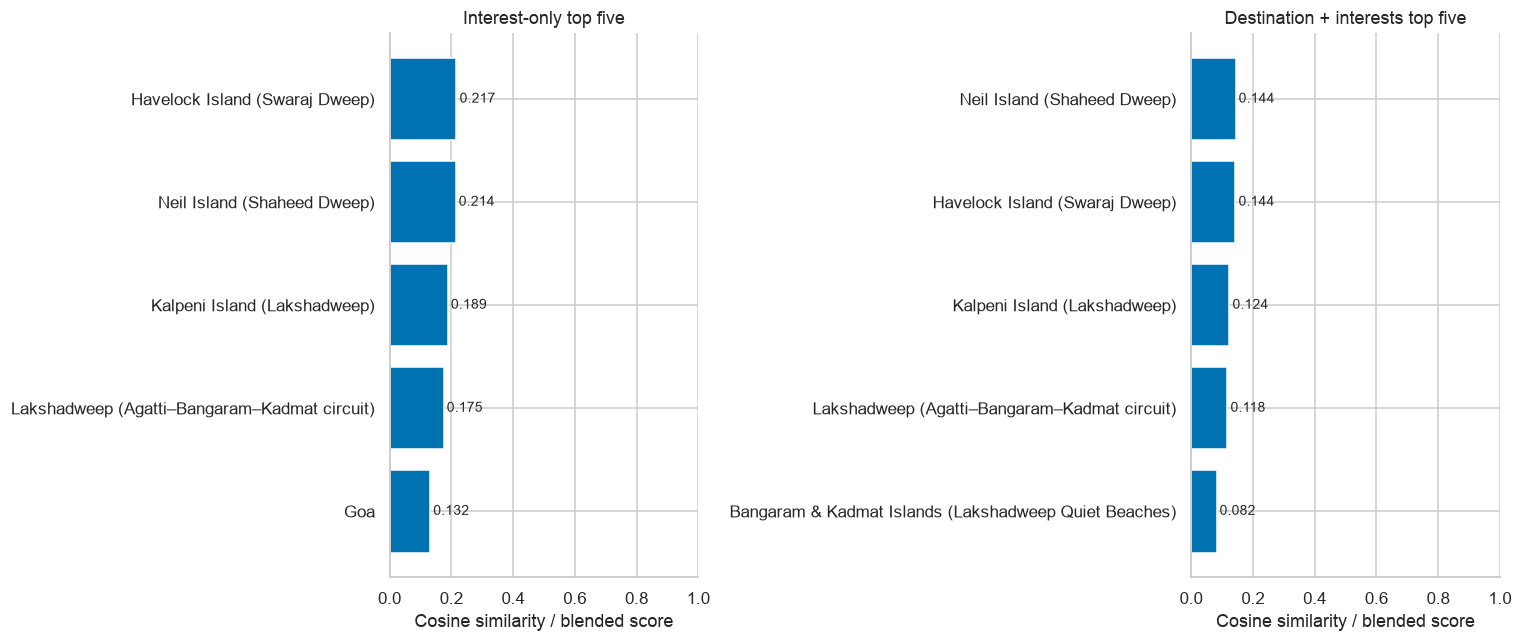

**Observations.** The two rankings above use the same fitted vocabulary. Adding a destination reference changes the signal mix; matching these interests does not verify seasonal or logistical suitability.

In [4]:
user_interests = ["beach", "water sports", "snorkelling", "island"]
interest_results = recommender.recommend(interests=user_interests, top_n=5)
combined_results = recommender.recommend(selected_destination=selected_id, interests=user_interests,
                                         destination_weight=0.4, top_n=5)
print("Interests:", ", ".join(user_interests))
print("Interest-only recommendations")
show_recommendations(interest_results)
print(f"Combined recommendations: {selected.destination_name} + interests")
show_recommendations(combined_results)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, results, title in [(axes[0], interest_results, "Interest-only top five"),
                           (axes[1], combined_results, "Destination + interests top five")]:
    values = results.iloc[::-1]
    ax.barh(values.destination_name, values.similarity_score, color="#0072b2")
    ax.set(title=title, xlabel="Cosine similarity / blended score", ylabel="", xlim=(0, 1))
    for y, score in enumerate(values.similarity_score):
        ax.text(score + 0.01, y, f"{score:.3f}", va="center", fontsize=9)
fig.tight_layout(); plt.show()
observe("The two rankings above use the same fitted vocabulary. Adding a destination reference changes "
        "the signal mix; matching these interests does not verify seasonal or logistical suitability.")

## 6. Visualize similarities among distinct destinations
Plot a small sample of unique destination names for interpretability. The diagonal is self-similarity and is excluded from actual recommendations. This small visualization uses a dense submatrix; the backend keeps its corpus representation sparse.

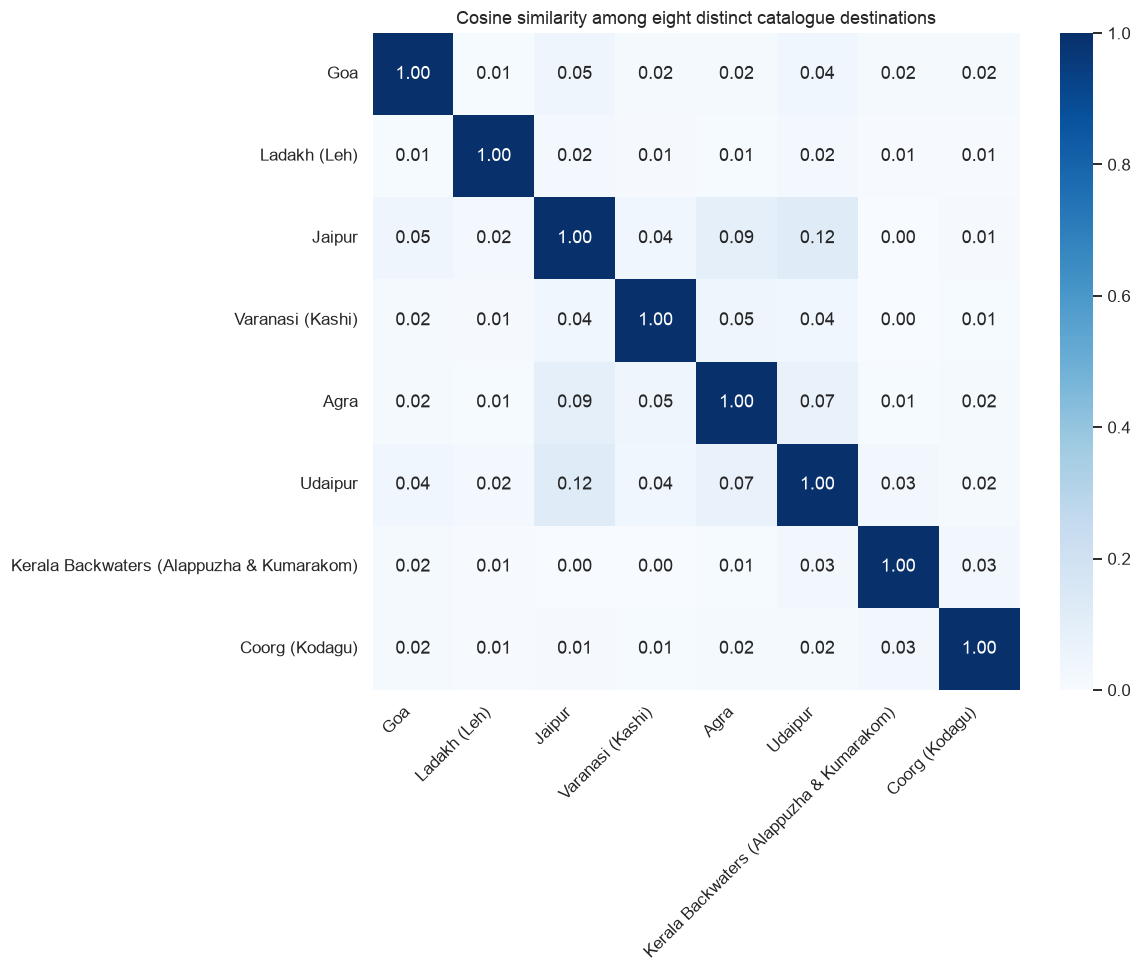

**Observations.** Off-diagonal values show textual overlap in this sample. Geographic terms and descriptive wording can affect similarity even when destinations differ in practical travel requirements.

In [5]:
sample = catalogue.assign(name_key=catalogue.destination_name.map(destination_key)).drop_duplicates("name_key").head(8)
positions = sample.index.to_numpy()
sample_similarity = cosine_similarity(matrix[positions])
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(sample_similarity, vmin=0, vmax=1, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=sample.destination_name, yticklabels=sample.destination_name, ax=ax)
ax.set_title("Cosine similarity among eight distinct catalogue destinations")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout(); plt.show()
observe("Off-diagonal values show textual overlap in this sample. Geographic terms and descriptive "
        "wording can affect similarity even when destinations differ in practical travel requirements.")

## 7. Basic evaluation: behavior checks and descriptive retrieval proxies
There are no labeled user preferences, interaction logs, or independent relevance judgments. Therefore we cannot report true precision, recall, or recommendation accuracy.

First validate score calculations, deterministic ranking, input handling, and duplicate exclusion. Then compare **shared trip-tag Jaccard overlap** with a seeded random baseline over one representative query per normalized destination name. Jaccard is intersection size divided by union size. Random candidates use one source representative per destination, excluding the query. The recommender can choose any candidate variant; this choice may affect overlap.

These tags already appear in TF-IDF input, so overlap is a descriptive sanity check, not independent or held-out evaluation. An additional interest-query table reports the fraction of top-five results containing the exact queried tag, with the same limitation.

Score, duplicate, determinism, and input validation checks passed.


,query_id,destination_name,returned_count,content_tag_jaccard,random_tag_jaccard
0,1,Goa,5,0.192,0.022
1,2,Ladakh (Leh),5,0.239,0.022
2,3,Jaipur,5,0.273,0.136
3,4,Varanasi (Kashi),5,0.157,0.152
4,5,Agra,5,0.477,0.142
5,6,Udaipur,5,0.407,0.033
6,7,Kerala Backwaters (Alappuzha & Kumarakom),5,0.082,0.000
7,8,Coorg (Kodagu),5,0.277,0.025
8,9,Ziro Valley,5,0.225,0.000
9,10,Mawlynnong & nearby (including Living Root Bri...,5,0.133,0.120


,content_tag_jaccard,random_tag_jaccard
mean,0.233,0.062
median,0.201,0.057


,interest,returned_count,exact_tag_fraction
0,beach,5,1.0
1,wildlife,5,0.8
2,heritage,5,1.0
3,trekking,5,0.6
4,wellness,3,1.0


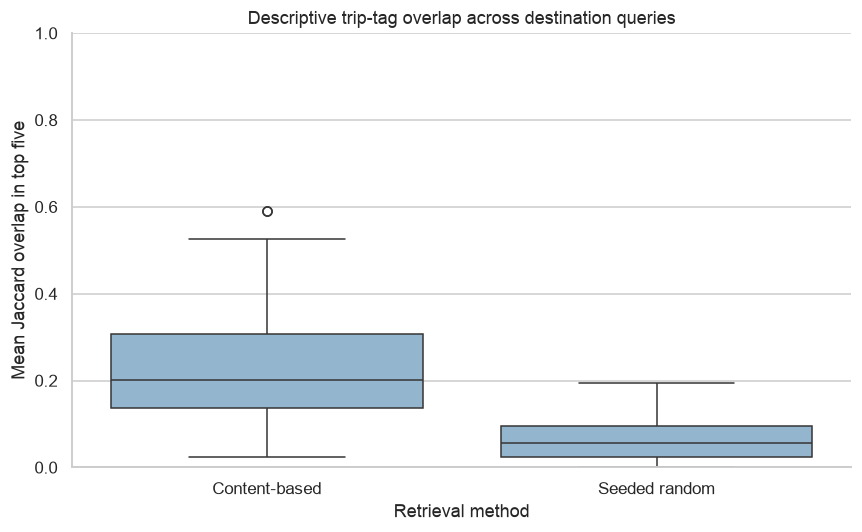

**Observations.** Evaluated 93 distinct-name queries. Mean top-five tag overlap is 0.233 for content retrieval and 0.062 for the seeded random baseline. 93 queries returned five results. These catalogue-derived proxies are not estimates of user satisfaction or held-out accuracy.

In [6]:
def validate_results(results, excluded_name=None):
    keys = results.destination_name.map(destination_key)
    assert keys.is_unique and len(results) <= 5
    assert results.similarity_score.between(0, 1).all()
    assert results.similarity_score.is_monotonic_decreasing
    assert (results.similarity_score > 0).all()
    if excluded_name is not None:
        assert not keys.eq(destination_key(excluded_name)).any()

for results in [destination_results, interest_results, combined_results]:
    validate_results(results)
validate_results(destination_results, selected.destination_name)
validate_results(combined_results, selected.destination_name)
manual_destination = cosine_similarity(matrix[0], matrix).ravel()
query_text = " ".join(user_interests)
manual_interest = cosine_similarity(recommender.vectorizer.transform([query_text]), matrix).ravel()
for row in combined_results.itertuples():
    position = int(np.flatnonzero(catalogue.id.eq(row.id))[0])
    assert np.isclose(row.similarity_score, 0.4 * manual_destination[position] + 0.6 * manual_interest[position])
assert recommender.recommend(interests="zzzxxyyqqq").empty
for kwargs in [{}, {"selected_destination": -999}, {"interests": "beach", "top_n": 0},
               {"selected_destination": 1, "interests": "zzzxxyyqqq"}]:
    try:
        recommender.recommend(**kwargs)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Expected validation failure for {kwargs}")
pd.testing.assert_frame_equal(destination_results, recommender.recommend(selected_destination=selected_id))
print("Score, duplicate, determinism, and input validation checks passed.")

def tag_jaccard(left, right):
    left, right = set(left), set(right)
    return len(left & right) / len(left | right) if left | right else 0.0

representatives = catalogue.assign(name_key=catalogue.destination_name.map(destination_key)).drop_duplicates("name_key")
rng = np.random.default_rng(42)
evaluation_rows = []
for query in representatives.itertuples():
    results = recommender.recommend(selected_destination=query.id, top_n=5)
    validate_results(results, query.destination_name)
    candidates = representatives.loc[representatives.name_key.ne(query.name_key)]
    baseline = candidates.iloc[rng.choice(len(candidates), size=min(5, len(candidates)), replace=False)]
    evaluation_rows.append({"query_id": query.id, "destination_name": query.destination_name,
        "returned_count": len(results),
        "content_tag_jaccard": np.mean([tag_jaccard(query.trip_types_clean, tags) for tags in results.trip_types_clean]) if len(results) else 0.0,
        "random_tag_jaccard": np.mean([tag_jaccard(query.trip_types_clean, tags) for tags in baseline.trip_types_clean])})
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.head(10).round(3))
display(evaluation[["content_tag_jaccard", "random_tag_jaccard"]].agg(["mean", "median"]).round(3))
interest_checks = []
for tag in ["beach", "wildlife", "heritage", "trekking", "wellness"]:
    results = recommender.recommend(interests=tag)
    validate_results(results)
    interest_checks.append({"interest": tag, "returned_count": len(results),
                            "exact_tag_fraction": np.mean([tag in tags for tags in results.trip_types_clean]) if len(results) else 0.0})
display(pd.DataFrame(interest_checks))
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=evaluation[["content_tag_jaccard", "random_tag_jaccard"]]
            .rename(columns={"content_tag_jaccard": "Content-based", "random_tag_jaccard": "Seeded random"}),
            ax=ax, color="#8ab6d6")
ax.set(title="Descriptive trip-tag overlap across destination queries", xlabel="Retrieval method", ylabel="Mean Jaccard overlap in top five", ylim=(0, 1))
fig.tight_layout(); plt.show()
observe(f"Evaluated {len(evaluation)} distinct-name queries. "
        f"Mean top-five tag overlap is {evaluation.content_tag_jaccard.mean():.3f} for content retrieval "
        f"and {evaluation.random_tag_jaccard.mean():.3f} for the seeded random baseline. "
        f"{evaluation.returned_count.eq(5).sum()} queries returned five results. "
        "These catalogue-derived proxies are not estimates of user satisfaction or held-out accuracy.")

## 8. Reuse in the Flask backend
The notebook imports the same Python class the backend can use. Example application initialization and request handling:

```python
from pathlib import Path
from recommender.content_recommender import ContentBasedRecommender

# Resolve relative to backend/app.py, not the server's working directory.
DATA_PATH = Path(__file__).resolve().parents[1] / "data/processed/india_tourism_processed.json"
recommender = ContentBasedRecommender.from_json(DATA_PATH)  # once at startup

# Inside a request handler, validate/catch ValueError as HTTP 400.
results = recommender.recommend(
    selected_destination=1,
    interests=["beach", "water sports"],
    destination_weight=0.4,
    top_n=5,
)
return jsonify(results.to_dict(orient="records"))
```

No Flask route is changed by this notebook. Returned fields include source IDs, destination names, geography, tags, duration, total similarity, and both component scores. Fully unknown interest-only queries return an empty list; a small catalogue or lack of positive similarity can return fewer than five results. All queries reuse the fitted vectorizer.

## 9. Findings, limitations, and final validation
The examples establish a working retrieval baseline with duplicate suppression and transparent scores. Conflicting source variants remain separate during fitting and the best matching variant supplies a result's facts. Geographic vocabulary, duplicate documents, and text lengths influence TF-IDF; later work can compare field weighting, distinct-entity IDF, reviewed tag vocabularies, and explicit user constraints.

Obtain independent relevance judgments or interaction data before claiming recommendation quality. Do not use these similarity scores to infer safety, current costs, or permits. The final checks confirm inputs remain unchanged and every catalogue query respects the exclusion rule.

In [7]:
for path, digest in input_hashes.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == digest, f"Input modified: {path.name}"
# Check all source variants, not only the representative queries used in the proxy evaluation.
for row in catalogue.itertuples():
    validate_results(recommender.recommend(selected_destination=row.id), row.destination_name)
assert matrix.shape[0] == len(records)
assert np.isfinite(matrix.data).all()
print("All checks passed. Original and processed datasets are unchanged; no model artifacts were written.")

All checks passed. Original and processed datasets are unchanged; no model artifacts were written.
